## TASK 4: Jupyter Notebook – Deep learning feed-forward network problem on cat and dog data with 10 hidden layers, and each layer must have 20 neurones/nodes.

In [1]:
import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator

## 1. Dataset Setup
Download the dataset if it is not already present locally.

In [2]:
extracted_path = 'PetImages'

if not os.path.exists(extracted_path):
    url = ('https://download.microsoft.com/download/3/E/1/'
           '3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip')
    zip_filename = 'cats_and_dogs.zip'

    if not os.path.exists(zip_filename):
        print(f'Downloading dataset from {url} ...')
        zip_path = tf.keras.utils.get_file(
            fname=zip_filename,
            origin=url,
            extract=False,
            cache_dir='.'
        )
        print('Download complete.')
    else:
        zip_path = zip_filename

    print('Extracting dataset...')
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')
    print('Dataset extracted.')
else:
    print(f'Dataset already present at "{extracted_path}".')

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 74s 0us/step
Download complete.
Extracting dataset...
Dataset extracted.


## 2. Remove Corrupted Images

In [3]:
from PIL import Image

num_skipped = 0

for folder_name in ['Cat', 'Dog']:
    folder_path = os.path.join(extracted_path, folder_name)

    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)

        try:
            img = Image.open(fpath)
            img.verify()
        except Exception:
            num_skipped += 1
            os.remove(fpath)

print('Corrupted images removed:', num_skipped)

C:\Users\Rahul\Desktop\DLCV_2026_2401030600031_sub1\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Corrupted images removed: 4


## 3. Data Generators (Train / Validation Split)

In [4]:
IMG_SIZE  = (64, 64)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.2
)

In [5]:
train_data = datagen.flow_from_directory(
    extracted_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True
)

Found 20000 images belonging to 2 classes.


In [6]:
validation_data = datagen.flow_from_directory(
    extracted_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

Found 4998 images belonging to 2 classes.


In [7]:
print('Class indices:', train_data.class_indices)

Class indices: {'Cat': 0, 'Dog': 1}


## 4. Build the Feed-Forward Network
Architecture:
- **Input:** Flatten 64×64×3 image → 12 288 features
- **10 Hidden Layers**, each with **20 neurons** and ReLU activation
- **Output Layer:** 1 neuron with Sigmoid activation (binary classification)

In [8]:
model = Sequential(name='FeedForward_CatDog')

# Input flattening layer
model.add(Flatten(input_shape=(64, 64, 3)))

# 10 hidden layers, each with 20 neurons
for layer_num in range(1, 11):
    model.add(Dense(20, activation='relu', name=f'hidden_{layer_num}'))

# Output layer for binary classification (Cat=0, Dog=1)
model.add(Dense(1, activation='sigmoid', name='output'))

C:\Users\Rahul\Desktop\DLCV_2026_2401030600031_sub1\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 5. Compile the Model

In [9]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 6. Model Summary

In [10]:
model.summary()

Model: "FeedForward_CatDog"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 20)             │       245,780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_4 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_5 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_6 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_7 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_8 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_9 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_10 (Dense)               │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,581 (974.93 KB)

 Trainable params: 249,581 (974.93 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the Model

In [11]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 115ms/step - accuracy: 0.5322 - loss: 0.6894 - val_accuracy: 0.5802 - val_loss: 0.6760
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 121ms/step - accuracy: 0.5770 - loss: 0.6763 - val_accuracy: 0.5804 - val_loss: 0.6738
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 68s 109ms/step - accuracy: 0.5901 - loss: 0.6712 - val_accuracy: 0.5742 - val_loss: 0.6762
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.5919 - loss: 0.6694 - val_accuracy: 0.5916 - val_loss: 0.6716
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 110ms/step - accuracy: 0.5904 - loss: 0.6695 - val_accuracy: 0.5920 - val_loss: 0.6702
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.5978 - loss: 0.6641 - val_accuracy: 0.5882 - val_loss: 0.6710
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 122ms/step - accuracy: 0.5985 - loss: 0.6677 - val_accuracy: 0.5478 - val_loss: 0.6865
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.6018 - loss: 0

## 8. Plot Training Results

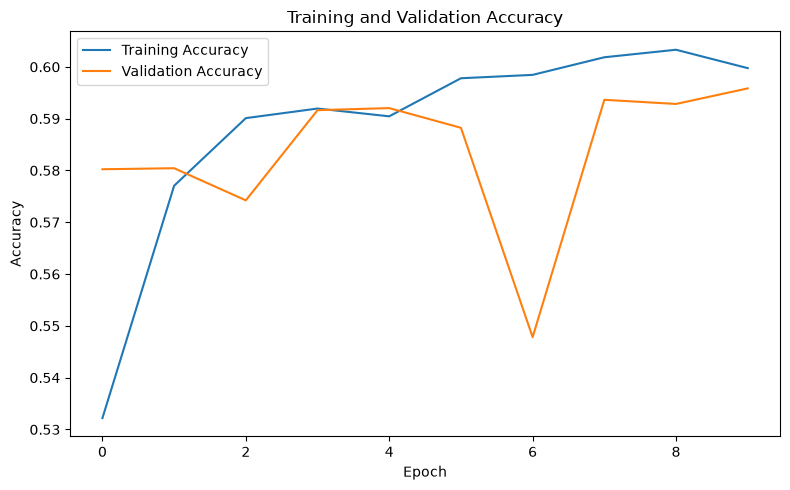

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],     label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

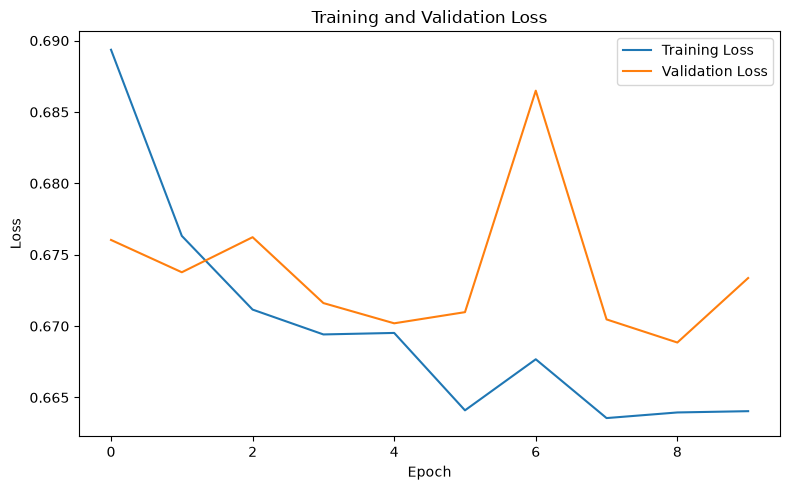

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Single-Image Prediction

In [14]:
from tensorflow.keras.preprocessing import image

img_path = 'PetImages/Cat/0.jpg'

img = image.load_img(img_path, target_size=(64, 64))

img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)[0][0]
label = 'DOG' if prediction >= 0.5 else 'CAT'

print(f'Raw prediction score: {prediction:.4f}')
print(f'Prediction: {label}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
Raw prediction score: 0.7957
Prediction: DOG


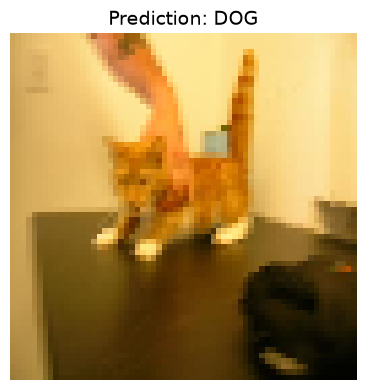

In [15]:
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis('off')
plt.title(f'Prediction: {label}', fontsize=14)
plt.tight_layout()
plt.show()